In [1]:

import pandas as pd
import datetime
import requests
from datetime import datetime as dt
from datetime import timedelta
import numpy as np
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
import plotly
import base64
from datetime import datetime

In [2]:

# Conexões 
producao_url = 'https://api.anbima.com.br/'
sandbox_url = 'https://api-sandbox.anbima.com.br/'
id_url = "https://api.anbima.com.br/oauth/access-token"
id_url = 'https://api.anbima.com.br/access-token'
### Define se dados vem de ambiente de producao ou sandbox ###

# Conexões 
producao_url = 'https://api.anbima.com.br/'
sandbox_url = 'https://api-sandbox.anbima.com.br/'
id_url = "https://api.anbima.com.br/oauth/access-token"
id_url_sandbox = "https://api-sandbox.anbima.com.br/oauth/access-token"

### Define se dados vem de ambiente de producao ou sandbox ###
producao = True

if producao:
  url = producao_url
  client_id = "wRGlvlj1bOW3"
  client_secret = "l4riAuRd0CUL"
  client_credentials = "wRGlvlj1bOW3:l4riAuRd0CUL"

else:
  url = sandbox_url
  client_id = "nZqmOGEuh6bg"
  client_secret = "BMXhChrji7ca"
  client_credentials = "nZqmOGEuh6bg:BMXhChrji7ca"


client_credentials = client_credentials.encode('ascii')
senhabytes = base64.b64encode(client_credentials)
senha = base64.b64decode(senhabytes)

def conectar(client_id, client_secret, client_credentials, url=url, id_url=id_url):
    client_credentials = client_credentials.encode('ascii')
    senhabytes = base64.b64encode(client_credentials)
    senha = base64.b64decode(senhabytes)
    senha_txt = senhabytes.decode('utf-8')
    body = {"grant_type": "client_credentials" }

    headers = {
            'content-type': 'application/json',
            'Authorization': 'Basic ' + senha_txt}
    
    
    request = requests.post(id_url, headers=headers, json=body, allow_redirects=True)
    informacoes = request.json()
    token = informacoes['access_token']  
    
    return { "content-type": "application/json",
            "client_id": f"{client_id}",
            "access_token": f"{token}"}
   

####  Header produção###
#headers = conectar('wRGlvlj1bOW3', 'l4riAuRd0CUL','wRGlvlj1bOW3:l4riAuRd0CUL', url)
headers = conectar('wRGlvlj1bOW3', 'l4riAuRd0CUL','wRGlvlj1bOW3:l4riAuRd0CUL', url, id_url)

### Header Sandbox ###   
#headers2 = conectar('nZqmOGEuh6bg', 'BMXhChrji7ca','nZqmOGEuh6bg:BMXhChrji7ca', url)
headers2 = conectar('nZqmOGEuh6bg', 'BMXhChrji7ca','nZqmOGEuh6bg:BMXhChrji7ca', url, id_url)


def extrair_json(http, headers = headers):
    request = requests.get(http, headers=headers)
    try:
        df = request.json()
        return df
    except ValueError:
        print('Erro')
        print(http)
        headers = conectar('wRGlvlj1bOW3', 'l4riAuRd0CUL','wRGlvlj1bOW3:l4riAuRd0CUL', url)    

In [3]:
def generate_months_years(start_date, end_date):
    start = datetime.strptime(start_date, "%Y-%m-%d")
    end = datetime.strptime(end_date, "%Y-%m-%d")
    current = start
    months_years = []

    while current <= end:
        months_years.append((current.month, current.year))
        # Move to the next month
        if current.month == 12:
            current = datetime(current.year + 1, 1, 1)
        else:
            current = datetime(current.year, current.month + 1, 1)

    return months_years


def extrair_json(http, headers = headers):
    request = requests.get(http, headers=headers)
    try:
        df = request.json()
        return df
    except ValueError:
        print('Erro')
        print(http)
        headers = conectar('wRGlvlj1bOW3', 'l4riAuRd0CUL','wRGlvlj1bOW3:l4riAuRd0CUL', url) 

In [4]:
data_inicial = '2024-01-01'
data_final = '2024-12-13'

df_hist_classe_sub = pd.DataFrame()    
codigo_classe = 'C0000146757'

months_years = generate_months_years(data_inicial, data_final)
df_hist_segmento = pd.DataFrame()  

lista_classe_sub = ['C0000540900',
'C0000158674',
'C0000317322',
'C0000497266',
'C0000154008',
'C0000470740',
'C0000146757',
'C0000237787',
'C0000266590']

lista_classe_sub2 = ['C0000133485',
'C0000195782',
'C0000196320',
'C0000212873',
'C0000236365',
'C0000237779',
'C0000239429',
'C0000240141',
'C0000242896',
'C0000242901',
'C0000244120',
'C0000246026',
'C0000273449',
'C0000294081',
'C0000302570',
'C0000310980',
'C0000316423',
'C0000497320']

for codigo_classe in lista_classe_sub:
    codigo_classe = codigo_classe
    for month, year in months_years:
        #print(month)
    
        segmento_hist_http = f'https://api.anbima.com.br/feed/fundos/v2/fundos/segmento-investidor/{codigo_classe}/patrimonio-liquido?mes-referencia={month}&ano-referencia={year}'
        request = requests.get(segmento_hist_http, headers=headers2)
        if request.status_code != 200:
            #print('Erro')
            continue
        json_hist_segmento = request.json()
            
        temp_hist_segmento = pd.json_normalize(json_hist_segmento['historico_segmento_investidor_fundo'])
    
        historico = json_hist_segmento ['historico_segmento_investidor_fundo'][0]
        distribuicao = historico['distribuicao_segmento_investidor']
        temp_hist_segmento = pd.DataFrame(distribuicao)
        temp_hist_segmento = temp_hist_segmento[temp_hist_segmento['percentual_patrimonio_liquido'] > 0.001]
        temp_hist_segmento['codigo_classe'] = json_hist_segmento['classe']['codigo_classe']
        temp_hist_segmento['nome_comercial'] = json_hist_segmento['classe']['nome_comercial']
        temp_hist_segmento['data_referencia'] = json_hist_segmento['historico_segmento_investidor_fundo'][0]['data_referencia']
        df_hist_segmento = pd.concat([df_hist_segmento, temp_hist_segmento], ignore_index=True)
    

In [5]:
display(df_hist_segmento)

,segmento_investidor,percentural_patrimonio_liquido,percentual_patrimonio_liquido,codigo_classe,nome_comercial,data_referencia
0,Corporate,11.07,11.07,C0000540900,ITAÚ INDEX PRÉ LP RF FIF CIC RESP LIMITADA,2024-01-31
1,MiddleMarket,7.53,7.53,C0000540900,ITAÚ INDEX PRÉ LP RF FIF CIC RESP LIMITADA,2024-01-31
2,Private,1.12,1.12,C0000540900,ITAÚ INDEX PRÉ LP RF FIF CIC RESP LIMITADA,2024-01-31
3,Varejo,3.58,3.58,C0000540900,ITAÚ INDEX PRÉ LP RF FIF CIC RESP LIMITADA,2024-01-31
4,Varejo Alta Renda,76.69,76.69,C0000540900,ITAÚ INDEX PRÉ LP RF FIF CIC RESP LIMITADA,2024-01-31
...,...,...,...,...,...,...
388,RPPS,93.80,93.80,C0000266590,SICREDI INSTITUCIONAL IRF-M FI RF LP,2024-10-31
389,Varejo,5.73,5.73,C0000266590,SICREDI INSTITUCIONAL IRF-M FI RF LP,2024-10-31
390,Poder Público,0.50,0.50,C0000266590,SICREDI INSTITUCIONAL IRF-M FI RF LP,2024-11-29
391,RPPS,93.79,93.79,C0000266590,SICREDI INSTITUCIONAL IRF-M FI RF LP,2024-11-29


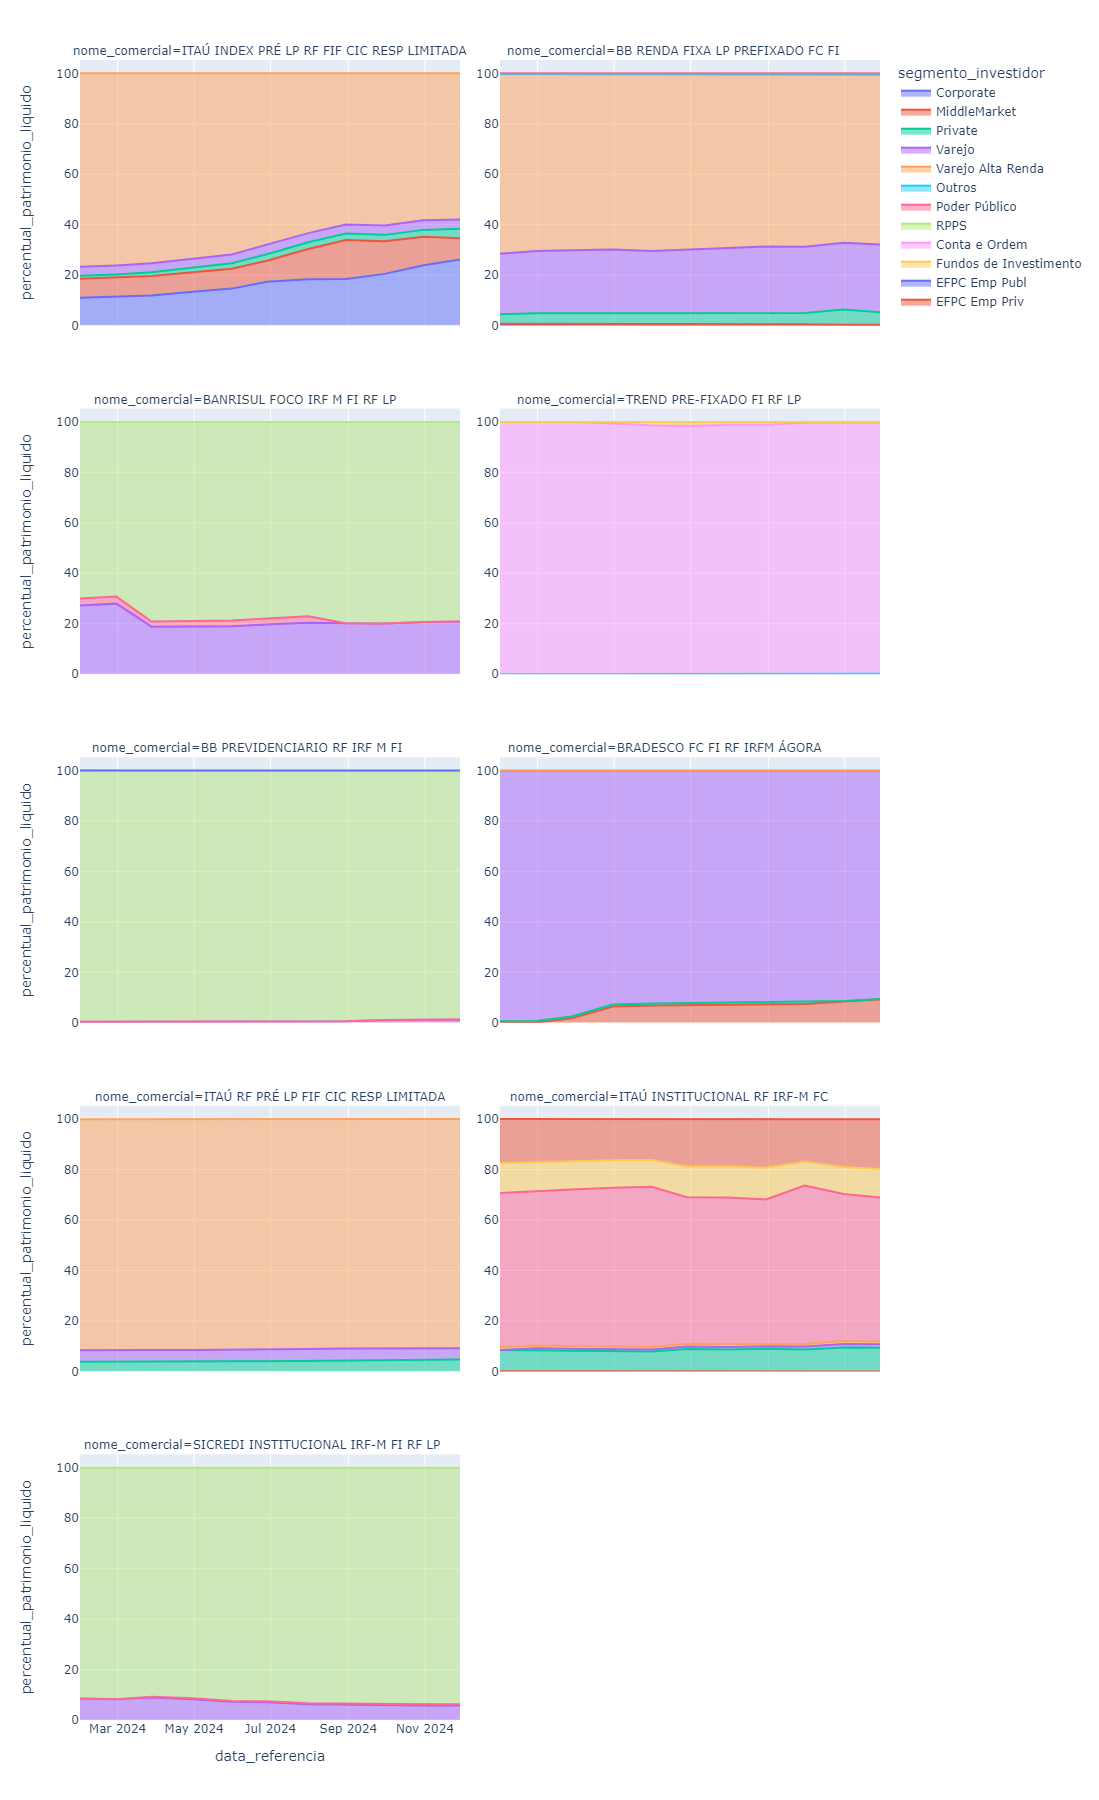

In [18]:
num = df_hist_segmento['nome_comercial'].nunique()
fig = px.area(df_hist_segmento
               , y='percentual_patrimonio_liquido'	
               , x='data_referencia'
               , facet_col_wrap=2      
               , facet_col = 'nome_comercial'
               , color='segmento_investidor'
               , height=num*200
               , width=1200
               , facet_col_spacing=0.05
               , facet_row_spacing=0.05
               
               )
fig.update_yaxes(matches=None) 
#fig.update_xaxes(matches=None)
fig.update_yaxes(showticklabels=True)
#fig.update_layout(hovermode='x')

fig.show()

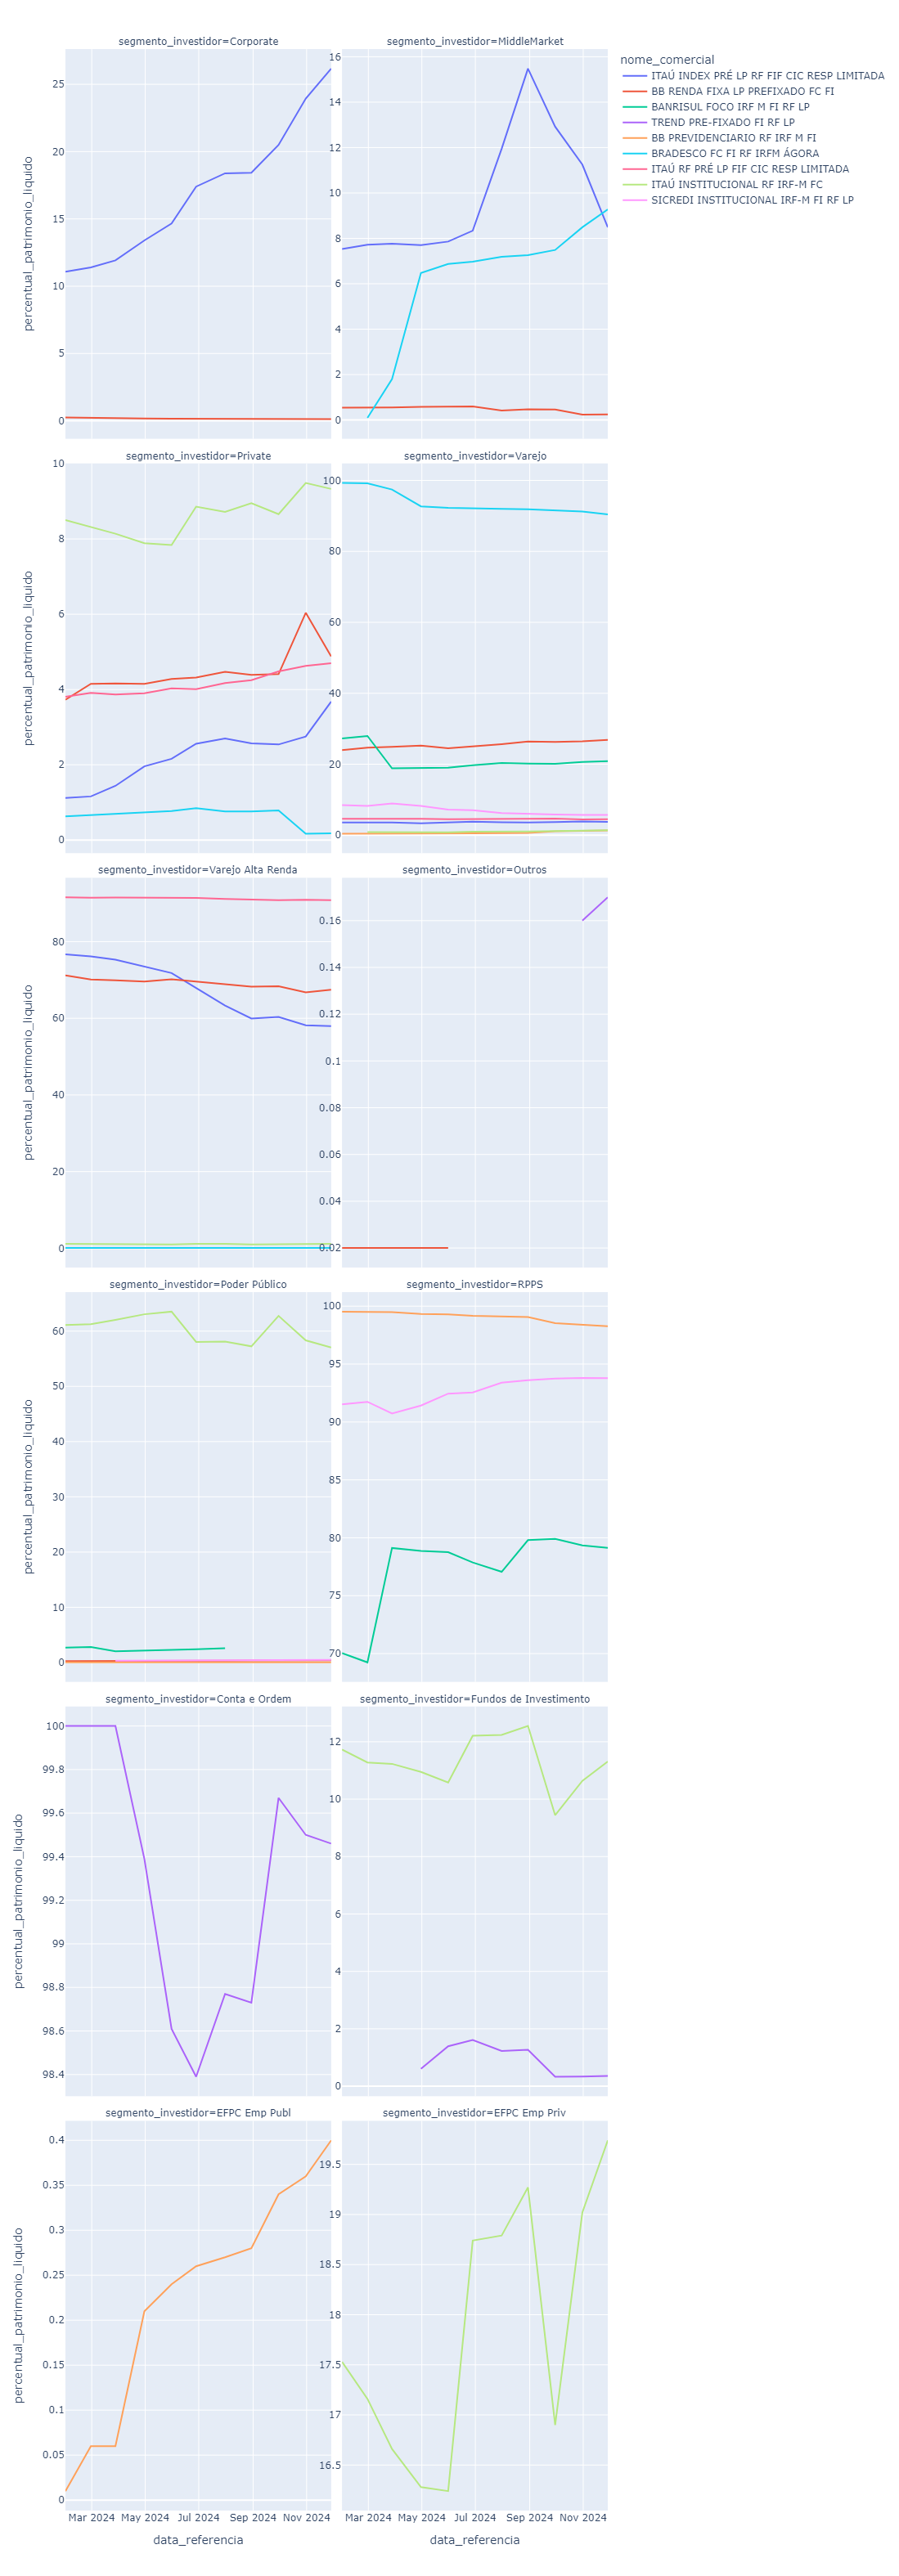

In [7]:
num = df_hist_segmento['nome_comercial'].nunique()
fig = px.line(df_hist_segmento
               , y='percentual_patrimonio_liquido'	
               , x='data_referencia'
               , facet_col_wrap=2      
               , facet_col = 'segmento_investidor'
               , color='nome_comercial'
               , height=num*350
               , width=1200
               , facet_col_spacing=0.02
               , facet_row_spacing=0.01
               )
fig.update_yaxes(matches=None) 
#fig.update_xaxes(matches=None)
fig.update_yaxes(showticklabels=True)

fig.show()

In [8]:
df_hist_segmento_ult = df_hist_segmento.loc[df_hist_segmento.groupby(['nome_comercial','segmento_investidor'])['data_referencia'].idxmax()]


In [9]:
display(df_hist_segmento_ult)

,segmento_investidor,percentural_patrimonio_liquido,percentual_patrimonio_liquido,codigo_classe,nome_comercial,data_referencia
144,Poder Público,2.58,2.58,C0000317322,BANRISUL FOCO IRF M FI RF LP,2024-07-31
153,RPPS,79.13,79.13,C0000317322,BANRISUL FOCO IRF M FI RF LP,2024-11-29
154,Varejo,20.87,20.87,C0000317322,BANRISUL FOCO IRF M FI RF LP,2024-11-29
216,EFPC Emp Publ,0.40,0.40,C0000154008,BB PREVIDENCIARIO RF IRF M FI,2024-11-29
217,Poder Público,0.04,0.04,C0000154008,BB PREVIDENCIARIO RF IRF M FI,2024-11-29
218,RPPS,98.26,98.26,C0000154008,BB PREVIDENCIARIO RF IRF M FI,2024-11-29
219,Varejo,1.30,1.30,C0000154008,BB PREVIDENCIARIO RF IRF M FI,2024-11-29
120,Corporate,0.13,0.13,C0000158674,BB RENDA FIXA LP PREFIXADO FC FI,2024-11-29
121,MiddleMarket,0.25,0.25,C0000158674,BB RENDA FIXA LP PREFIXADO FC FI,2024-11-29
85,Outros,0.02,0.02,C0000158674,BB RENDA FIXA LP PREFIXADO FC FI,2024-05-31


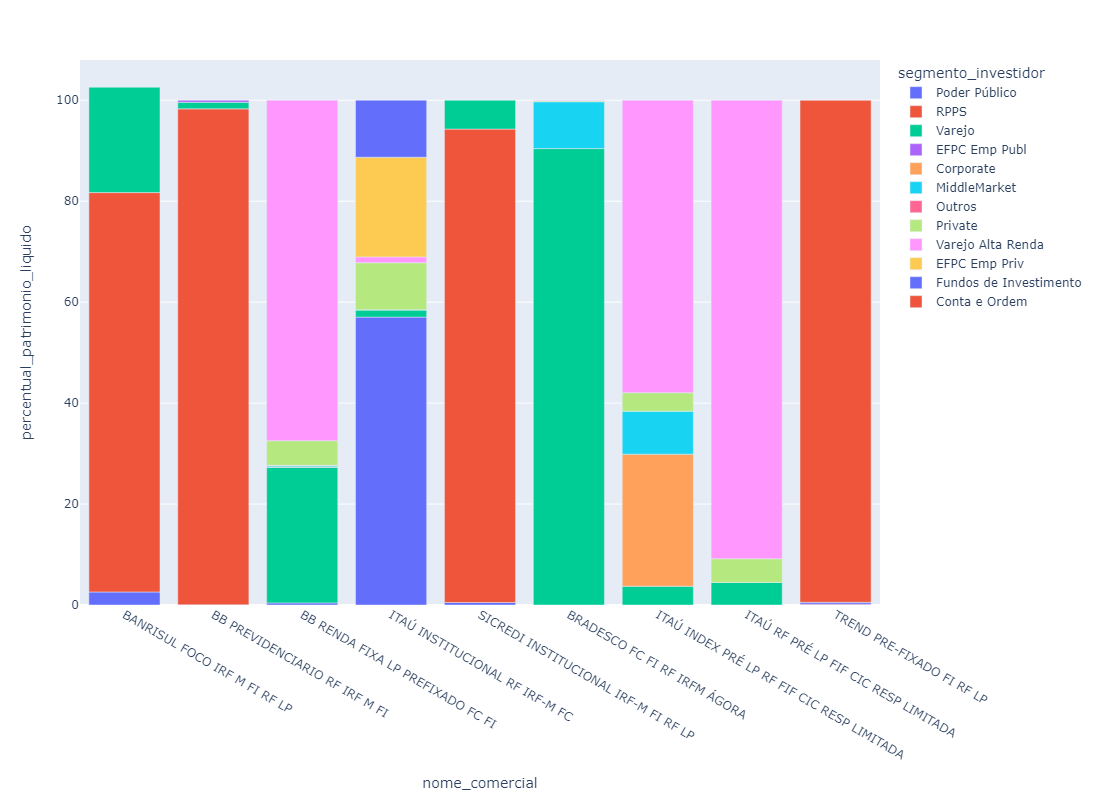

In [11]:
num = df_hist_segmento['nome_comercial'].nunique()
fig = px.bar(df_hist_segmento_ult
               , y='percentual_patrimonio_liquido'	
               , x='nome_comercial'
               , color='segmento_investidor'
               , height=800
               , width=1000             
               )
fig.update_yaxes(matches=None) 
#fig.update_xaxes(matches=None)
fig.update_yaxes(showticklabels=True)
#fig.update_layout(hovermode='x unified')

fig.show()

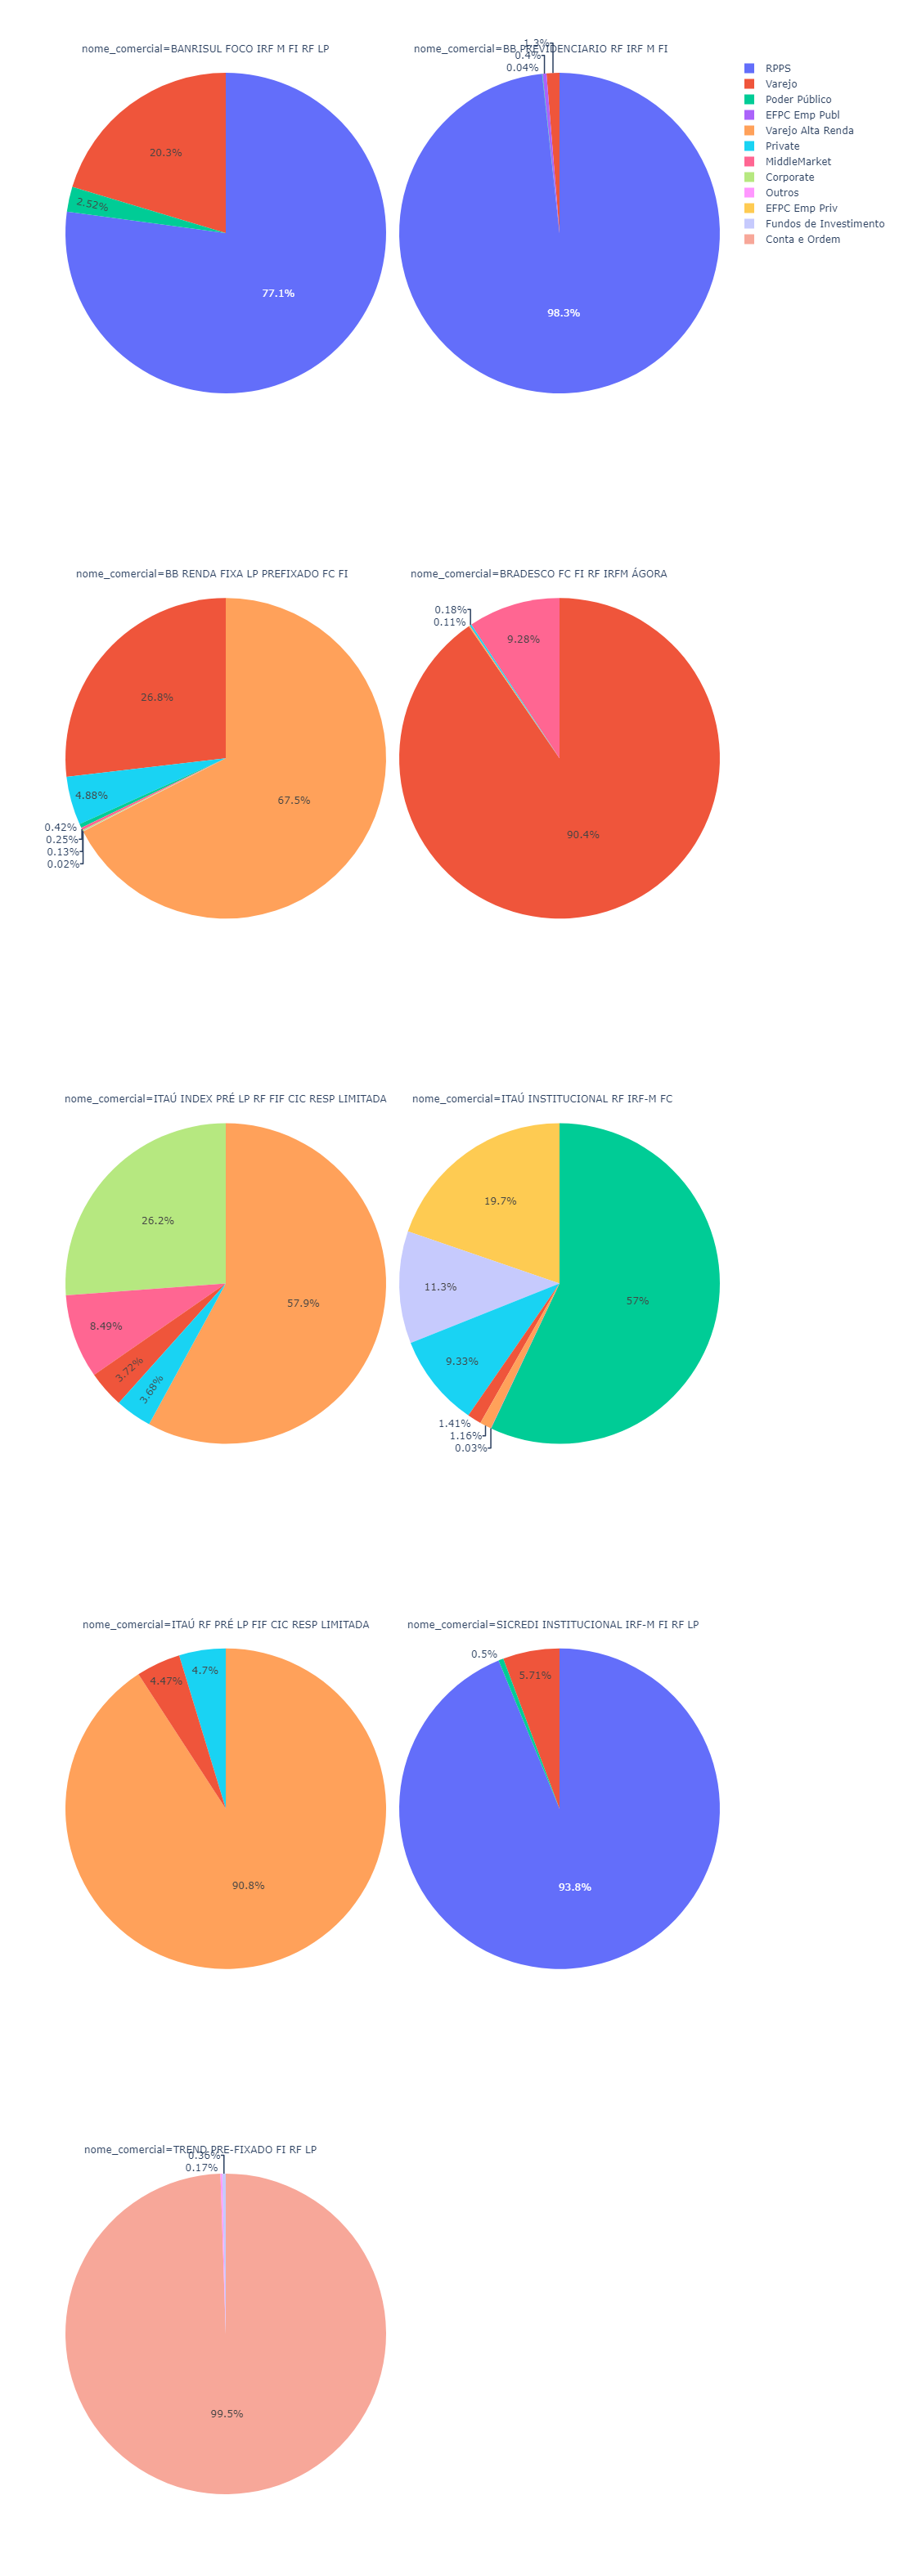

In [14]:
fig = px.pie(df_hist_segmento_ult
               , values='percentual_patrimonio_liquido'	
               , names='segmento_investidor'
               , facet_col_wrap=2      
               , facet_col = 'nome_comercial'
               , height=num*350
               , width=1000             
               )
fig.update_yaxes(matches=None) 
#fig.update_xaxes(matches=None)
fig.update_yaxes(showticklabels=True)
#fig.update_layout(hovermode='x unified')

fig.show()